# Simulated Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# for loading DLPFC12 data
def load_DLPFC(root_dir='./DLPFC12', section_id='151507'):
    # 151507, ..., 151676
    # 12 in total, 7 layers
    # 151507: n_obs × n_vars = 4221 × 33538
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file=section_id+'_filtered_feature_bc_matrix.h5')
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    print("spot num", ad)
    return ad


In [3]:
ad = load_DLPFC(root_dir='/hpc/group/hickeylab/fl135/pkl_data', section_id='151669')

spot num AnnData object with n_obs × n_vars = 3636 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


In [4]:
ad_target = load_DLPFC(root_dir='/hpc/group/hickeylab/fl135/pkl_data', section_id='151670')


spot num AnnData object with n_obs × n_vars = 3484 × 33538
    obs: 'in_tissue', 'array_row', 'array_col', 'original_clusters'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


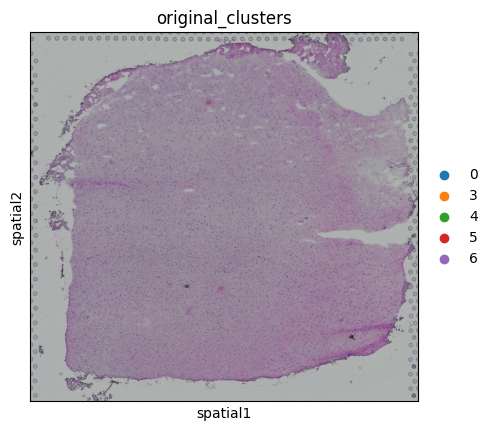

In [5]:
sc.pl.spatial(ad, color='original_clusters', spot_size=1.5)

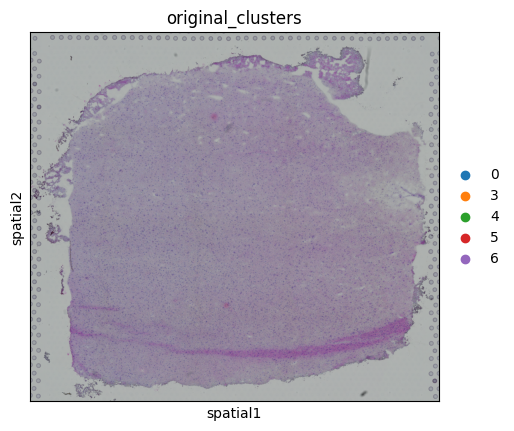

In [6]:
sc.pl.spatial(ad_target, color='original_clusters', spot_size=1.5)

0 of 3484
3483 of 3484


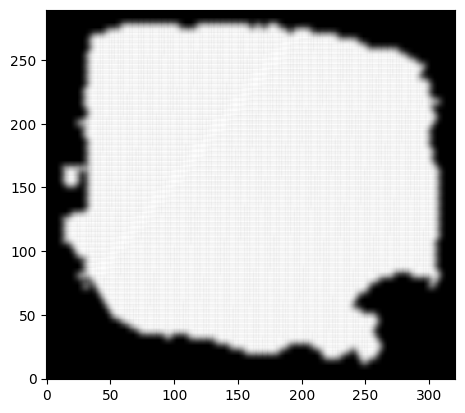

In [7]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 3636
3635 of 3636


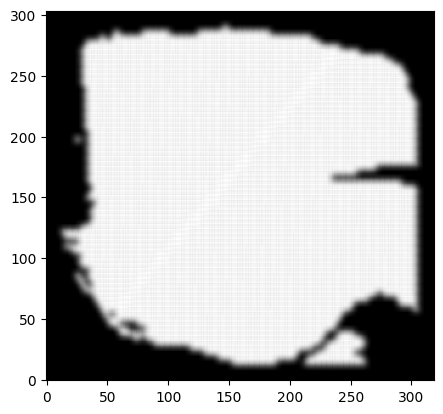

In [8]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

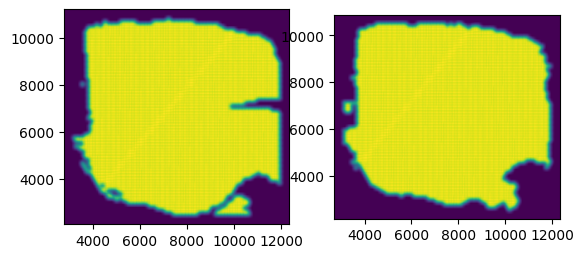

In [9]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 5min 43s, sys: 9.94 s, total: 5min 53s
Wall time: 5min 5s


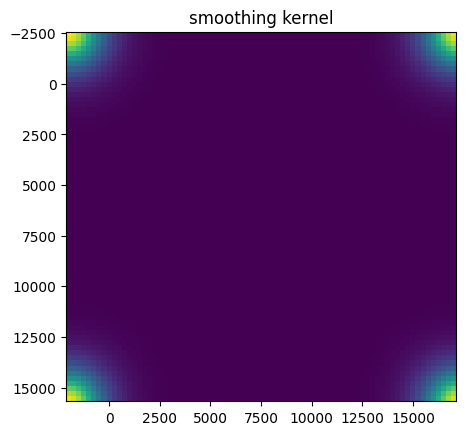

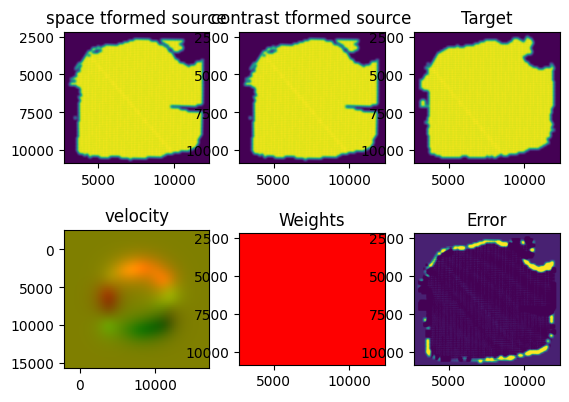

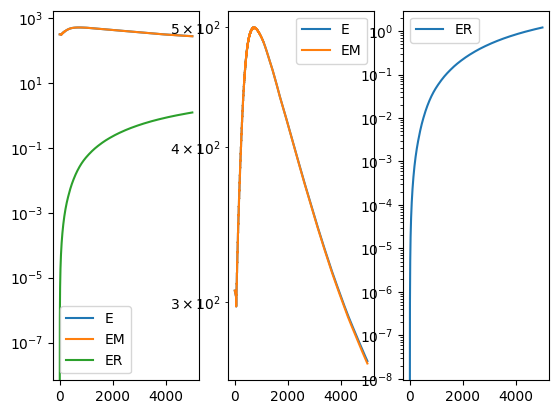

In [10]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            # 'niter':10000,
            # 'pointsI':pointsI,
            # 'pointsJ':pointsJ,
            # 'L':L,'T':T,
            'niter':5000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.1, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [11]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']


In [12]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

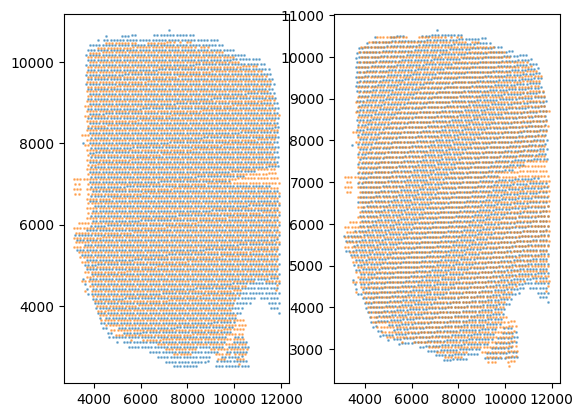

In [13]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.5, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.5, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.5, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

In [14]:
from sklearn.metrics import pairwise

f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)
alignment = pairwise.euclidean_distances(f1, f2)
alignment = np.exp(-alignment)

alignment_df = pd.DataFrame(alignment)


In [21]:
# Save as .pkl
alignment_df.to_pickle("/hpc/group/hickeylab/fl135/pkl_data/151669_151670_AlignmentPi.pkl")

## LAA

In [15]:
# LAA
#calculate laywise bar, result needs to be devided by total number to calculate the accuracy rate
def cal_layer_based_alignment_result(alignment, s1, s2):
    #fei added
    labels = []
    labels.extend(s1.obs['original_clusters'])
    labels.extend(s2.obs['original_clusters'])

    res = []
    l_dict = {"0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "6": 6}
    cnt0 = 0
    cnt1 = 0
    cnt2 = 0
    cnt3 = 0
    cnt4 = 0
    cnt5 = 0
    cnt6 = 0
    for i, elem in enumerate(alignment):
        if np.max(elem) - np.min(elem) != 0: # paste2 might have spots that are not aligned to any other spots. paste might have negative alignment
            if labels[i] == '-1' or labels[elem.argmax() + alignment.shape[0]] == '-1':
                continue
            if l_dict[labels[i]] == l_dict[labels[elem.argmax() + alignment.shape[0]]]:
                cnt0 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 1:
                cnt1 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 2:
                cnt2 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 3:
                cnt3 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 4:
                cnt4 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 5:
                cnt5 += 1
            if abs(l_dict[labels[i]] - l_dict[labels[elem.argmax() + alignment.shape[0]]]) == 6:
                cnt6 += 1
    res.extend([cnt0, cnt1, cnt2, cnt3, cnt4, cnt5, cnt6])
    return res

In [16]:
res = cal_layer_based_alignment_result(alignment, ad, ad_target)
res

[1420, 541, 694, 691, 36, 62, 40]

In [17]:
divisor = alignment.shape[0]
LAA_result = [num / divisor for num in res]
print(LAA_result)

[0.40757749712973596, 0.1552812858783008, 0.1991963260619977, 0.19833524684270953, 0.010332950631458095, 0.017795637198622274, 0.011481056257175661]


In [18]:
alignment.shape

(3484, 3636)

## ARI

In [19]:
from sklearn.metrics import adjusted_rand_score


def compute_alignment_ari(sliceA, sliceB, pi):
    mapped_clusters = []
    for j in range(pi.shape[1]):
        mapping = pi[:, j]
        #original: if np.sum(mapping) > 0:
        if np.max(mapping) - np.min(mapping) != 0:
            i = np.argmax(mapping)
            mapped_clusters.append(sliceA.obs['original_clusters'][i])
        else:
            mapped_clusters.append("NULL")
    assert len(sliceB.obs['original_clusters']) == len(mapped_clusters)
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []
    for i in range(len(sliceB.obs['original_clusters'])):
        if mapped_clusters[i] != "NULL":
            true_clusters_mapped_region.append(sliceB.obs['original_clusters'][i])
            mapped_clusters_mapped_region.append(mapped_clusters[i])

    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
    return ari

In [20]:
ari = compute_alignment_ari(ad_target, ad, alignment)
ari

0.8926800920525022

## 3D

In [22]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,AAACAAGTATCTCCCA-1,4
1,AAACACCAATAACTGC-1,6
2,AAACAGAGCGACTCCT-1,3
3,AAACAGGGTCTATATT-1,4
4,AAACATTTCCCGGATT-1,6


In [23]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 0
results1['slice'] = '151669'
results1

,index,original_clusters,X,Y,Z,slice
0,AAACAAGTATCTCCCA-1,4,10053.626667,8535.530637,0,151669
1,AAACACCAATAACTGC-1,6,4357.011195,9426.946382,0,151669
2,AAACAGAGCGACTCCT-1,3,9552.155627,4406.323546,0,151669
3,AAACAGGGTCTATATT-1,4,3931.431139,8029.286853,0,151669
4,AAACATTTCCCGGATT-1,6,9686.463327,9773.288185,0,151669
...,...,...,...,...,...,...
3631,TTGTTGTGTGTCAAGA-1,3,8367.739570,6306.254130,0,151669
3632,TTGTTTCACATCCAGG-1,6,5930.515760,9349.788435,0,151669
3633,TTGTTTCATTAGTCTA-1,6,5108.297673,9560.599833,0,151669
3634,TTGTTTCCATACAACT-1,5,4901.927930,7824.084665,0,151669


In [24]:
results1.to_csv('151669.csv', index=False)